https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=9311206

# Early-Stage Diabetes Risk Prediction Analysis

This notebook demonstrates a complete machine learning workflow to predict early-stage diabetes risk. We cover the entire pipeline, including dataset downloading, statistical description, data translation, multi-model evaluation, and detailed metrics comparison using confusion matrices.

https://www.kaggle.com/datasets/ishandutta/early-stage-diabetes-risk-prediction-dataset/data

In [ ]:
# from google.colab import files

# uploaded = files.upload()

# for fn in uploaded.keys():
#   print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')


### دانلود و بارگذاری دیتاست پیش‌بینی ریسک دیابت از Kaggle

برای دانلود مستقیم از Kaggle در محیط کولب، ابتدا باید فایل `kaggle.json` (که حاوی توکن API شماست) را آپلود کنید. پس از آپلود، کد زیر پوشه لازم را ایجاد کرده، دیتاست را دانلود و در یک دیتافریم لود می‌کند.

In [ ]:
import os
import pandas as pd
from google.colab import files

# بررسی وجود پوشه کمکی یا فایل کگل
if not os.path.exists('/root/.kaggle'):
    os.makedirs('/root/.kaggle')

# در صورتی که فایل را قبلاً آپلود نکرده‌اید، این خط را فعال کنید تا فایل را آپلود کنید:
# uploaded = files.upload()
# !cp kaggle.json /root/.kaggle/
# !chmod 600 /root/.kaggle/kaggle.json

# دانلود دیتاست از کگل
!kaggle datasets download -d ishandutta/early-stage-diabetes-risk-prediction-dataset

# استخراج فایل زیپ
import zipfile
with zipfile.ZipFile('early-stage-diabetes-risk-prediction-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('diabetes_data')

# بارگذاری در دیتافریم
df_diabetes = pd.read_csv('diabetes_data/diabetes_data_upload.csv')

# نمایش ۵ سطر اول
display(df_diabetes.head())

Dataset URL: https://www.kaggle.com/datasets/ishandutta/early-stage-diabetes-risk-prediction-dataset
License(s): DbCL-1.0
100% 2.52k/2.52k [00:00<00:00, 5.27MB/s]



,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


## 1. Data Acquisition

In this step, we programmatically download the 'Early Stage Diabetes Risk Prediction Dataset' from Kaggle using the official Kaggle CLI tool, extract the archive, and load the CSV data into a Pandas DataFrame.

In [ ]:
# ۱. تعریف دیکشنری ترجمه برای نام ستون‌ها
column_translation = {
    'Age': 'سن',
    'Gender': 'جنسیت',
    'Polyuria': 'تکرر_ادرار',
    'Polydipsia': 'پرنوشی',
    'sudden weight loss': 'کاهش_ناگهانی_وزن',
    'weakness': 'ضعف',
    'Polyphagia': 'پرخوری',
    'Genital thrush': 'برفک_تناسلی',
    'visual blurring': 'تاری_دید',
    'Itching': 'خارش',
    'Irritability': 'تحریک‌پذیری',
    'delayed healing': 'تاخیر_در_بهبود_زخم',
    'partial paresis': 'فلج_نسبی_عضلات',
    'muscle stiffness': 'سفتی_عضلات',
    'Alopecia': 'ریزش_مو',
    'Obesity': 'چاقی',
    'class': 'کلاس_هدف'
}

# ۲. تعریف دیکشنری برای ترجمه مقادیر داخل سلول‌ها
value_translation = {
    'Yes': 'بله',
    'No': 'خیر',
    'Male': 'مرد',
    'Female': 'زن',
    'Positive': 'مثبت',
    'Negative': 'منفی'
}

# کپی از دیتافریم اصلی
df_diabetes_fa = df_diabetes.copy()

# ترجمه مقادیر درون جدول
df_diabetes_fa = df_diabetes_fa.replace(value_translation)

# تغییر نام ستون‌ها به فارسی
df_diabetes_fa = df_diabetes_fa.rename(columns=column_translation)

# نمایش نمونه‌ای از دیتافریم جدید
print("نمونه‌ای از دیتافریم ترجمه شده به فارسی:")
display(df_diabetes_fa.head())

نمونه‌ای از دیتافریم ترجمه شده به فارسی:


,سن,جنسیت,تکرر_ادرار,پرنوشی,کاهش_ناگهانی_وزن,ضعف,پرخوری,برفک_تناسلی,تاری_دید,خارش,تحریک‌پذیری,تاخیر_در_بهبود_زخم,فلج_نسبی_عضلات,سفتی_عضلات,ریزش_مو,چاقی,کلاس_هدف
0,40,مرد,خیر,بله,خیر,بله,خیر,خیر,خیر,بله,خیر,بله,خیر,بله,بله,بله,مثبت
1,58,مرد,خیر,خیر,خیر,بله,خیر,خیر,بله,خیر,خیر,خیر,بله,خیر,بله,خیر,مثبت
2,41,مرد,بله,خیر,خیر,بله,بله,خیر,خیر,بله,خیر,بله,خیر,بله,بله,خیر,مثبت
3,45,مرد,خیر,خیر,بله,بله,بله,بله,خیر,بله,خیر,بله,خیر,خیر,خیر,خیر,مثبت
4,60,مرد,بله,بله,بله,بله,بله,خیر,بله,بله,بله,بله,بله,بله,بله,بله,مثبت


## 2. Localization (Persian Translation)

To facilitate localized reporting, the columns and categorical features (such as binary responses and class definitions) are mapped to their Persian equivalents, generating a mirrored Persian DataFrame (`df_diabetes_fa`).

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ۱. نمایش اطلاعات کلی و مقادیر گم‌شده (Missing Values)
print("--- اطلاعات کلی دیتاست ---")
print(df_diabetes.info())

# ۲. آمارهای توصیفی برای سن (تنها ویژگی عددی پیوسته)
print("\n--- آمارهای توصیفی سن (Age) ---")
display(df_diabetes['Age'].describe().to_frame())

# ۳. توزیع متغیر هدف (Class) - مثبت یا منفی بودن ریسک دیابت
print("\n--- توزیع فراوانی کلاس هدف (Class) ---")
class_counts = df_diabetes['class'].value_counts()
class_pct = df_diabetes['class'].value_counts(normalize=True) * 100
display(pd.DataFrame({'تعداد': class_counts, 'درصد': class_pct}))

--- اطلاعات کلی دیتاست ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16 

,Age
count,520.000000
mean,48.028846
std,12.151466
min,16.000000
25%,39.000000
50%,47.500000
75%,57.000000
max,90.000000



--- توزیع فراوانی کلاس هدف (Class) ---


,تعداد,درصد
class,,
Positive,320,61.538462
Negative,200,38.461538


## 3. Exploratory Data Analysis & Descriptive Statistics

Here, we investigate the dataset's characteristics, analyzing missing data, computing summary statistics for numerical attributes (like Age), and looking at class prevalence across target labels.

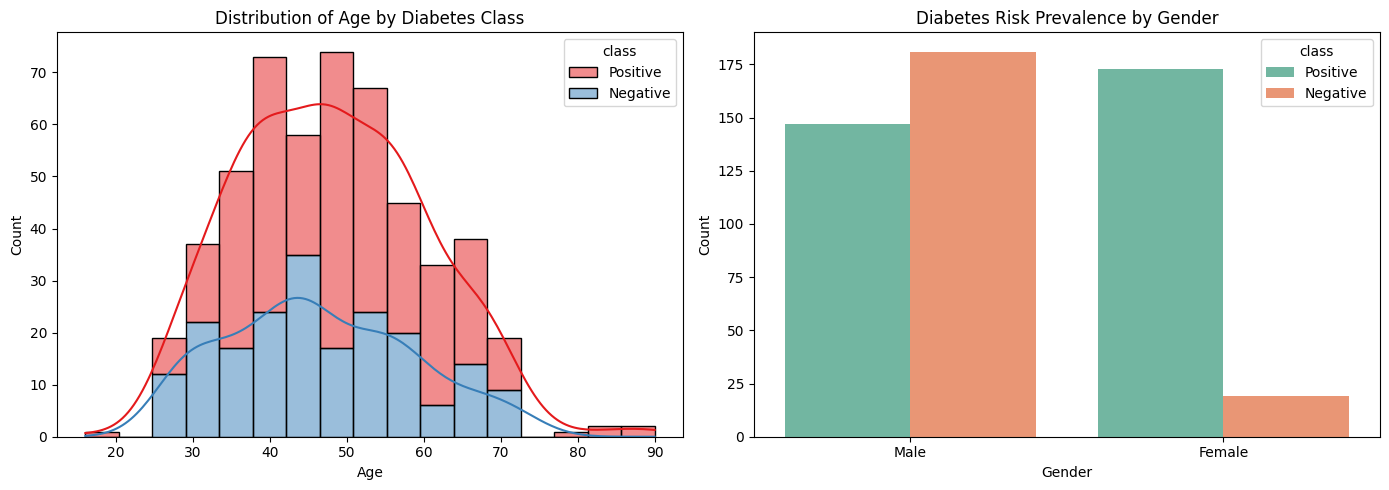

In [ ]:
# ۴. رسم نمودار توزیع سن و توزیع کلاس هدف
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# نمودار توزیع سن
sns.histplot(data=df_diabetes, x='Age', hue='class', kde=True, ax=axes[0], multiple="stack", palette='Set1')
axes[0].set_title('Distribution of Age by Diabetes Class')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# نمودار توزیع جنسیت (Gender)
sns.countplot(data=df_diabetes, x='Gender', hue='class', ax=axes[1], palette='Set2')
axes[1].set_title('Diabetes Risk Prevalence by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
# ۵. بررسی نرخ شیوع (Prevalence) علائم مختلف به تفکیک کلاس هدف
print("\n--- بررسی توزیع علائم مختلف (Symptoms Distribution) ---")
symptoms = [col for col in df_diabetes.columns if col not in ['Age', 'Gender', 'class']]

# ایجاد دیتافریم برای بررسی نسبت پاسخ‌های مثبت (Yes) در هر ویژگی به تفکیک کلاس
symptom_analysis = []
for sym in symptoms:
    pos_class_yes = df_diabetes[df_diabetes['class'] == 'Positive'][sym].value_counts(normalize=True).get('Yes', 0) * 100
    neg_class_yes = df_diabetes[df_diabetes['class'] == 'Negative'][sym].value_counts(normalize=True).get('Yes', 0) * 100
    symptom_analysis.append({
        'Symptom': sym,
        'Positive Class (Yes %)': round(pos_class_yes, 2),
        'Negative Class (Yes %)': round(neg_class_yes, 2)
    })

df_symptoms_summary = pd.DataFrame(symptom_analysis).sort_values(by='Positive Class (Yes %)', ascending=False)
display(df_symptoms_summary)


--- بررسی توزیع علائم مختلف (Symptoms Distribution) ---


,Symptom,Positive Class (Yes %),Negative Class (Yes %)
0,Polyuria,75.94,7.5
1,Polydipsia,70.31,4.0
3,weakness,68.12,43.5
10,partial paresis,60.00,16.0
4,Polyphagia,59.06,24.0
2,sudden weight loss,58.75,14.5
6,visual blurring,54.69,29.0
7,Itching,48.12,49.5
9,delayed healing,47.81,43.0
11,muscle stiffness,42.19,30.0


## 4. Feature and Symptom Prevalence Analysis

We analyze clinical symptoms across patients to observe how the percentage of 'Yes' responses varies between positive and negative diabetes risk classes.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import pandas as pd
import numpy as np

# ۱. پیش‌پردازش و تبدیل متغیرهای دسته‌بندی به عددی
df_encoded = df_diabetes.copy()
label_encoders = {}

for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        label_encoders[col] = le

# ۲. جداسازی ویژگی‌ها و متغیر هدف
X = df_encoded.drop(columns=['class'])
y = df_encoded['class']

# ۳. تقسیم داده‌ها به مجموعه‌های آموزش و تست
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ۴. تعریف مدل‌ها (شامل مدل‌های قبلی و مدل‌های جدید خواسته شده)
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest (RFC)': RandomForestClassifier(random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(),
    'Support Vector Machine': SVC(random_state=42),
    # ۵ مدل اضافی جدید به همراه شبکه عصبی
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'Bagging Classifier': BaggingClassifier(random_state=42),
    'Naive Bayes (Gaussian)': GaussianNB(),
    'Neural Network (MLP)': MLPClassifier(max_iter=1000, random_state=42)
}

# ۵. آموزش و ارزیابی مدل‌ها
results_list = []

for name, model in models.items():
    # آموزش مدل
    model.fit(X_train, y_train)
    # پیش‌بینی
    y_pred = model.predict(X_test)

    # محاسبه معیارهای ارزیابی
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results_list.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

# نمایش نتایج در قالب جدول مقایسه‌ای
df_results = pd.DataFrame(results_list).sort_values(by='Accuracy', ascending=False)
print("--- جدول مقایسه عملکرد مدل‌های مختلف (۱۰ مدل شامل شبکه عصبی) ---")
display(df_results)

--- جدول مقایسه عملکرد مدل‌های مختلف (۱۰ مدل شامل شبکه عصبی) ---


,Model,Accuracy,Precision,Recall,F1-Score
7,Extra Trees,1.0000,1.0000,1.0000,1.0000
2,Random Forest (RFC),0.9904,1.0000,0.9844,0.9921
1,Decision Tree,0.9904,1.0000,0.9844,0.9921
5,Gradient Boosting,0.9904,1.0000,0.9844,0.9921
8,Bagging Classifier,0.9808,1.0000,0.9688,0.9841
0,Logistic Regression,0.9423,0.9833,0.9219,0.9516
6,AdaBoost,0.9423,0.9833,0.9219,0.9516
9,Naive Bayes (Gaussian),0.9423,0.9677,0.9375,0.9524
10,Neural Network (MLP),0.9423,0.9833,0.9219,0.9516
3,K-Nearest Neighbors (KNN),0.9327,0.9831,0.9062,0.9431


## 5. Machine Learning Modeling & Comparison

We train and evaluate 10 different machine learning classifiers from `scikit-learn`, including Logistic Regression, Decision Trees, Ensemble methods, Naïve Bayes, and a Multi-Layer Perceptron (MLP) Neural Network. Results are ordered by overall validation accuracy.

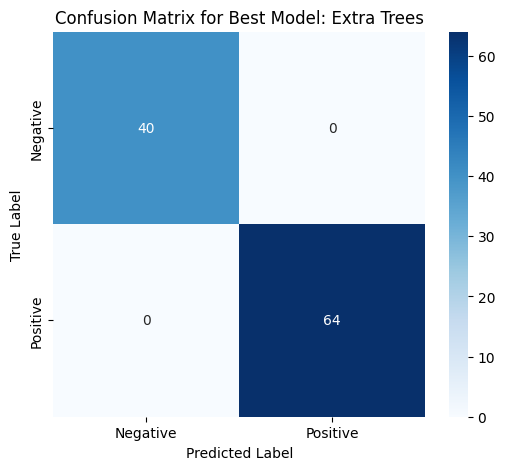

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ۱. پیدا کردن نام بهترین مدل بر اساس بیشترین دقت (Accuracy)
best_model_name = df_results.iloc[0]['Model']
best_model = models[best_model_name]

# ۲. پیش‌بینی مجدد داده‌های تست توسط بهترین مدل
y_pred_best = best_model.predict(X_test)

# ۳. محاسبه ماتریس درهم‌ریختگی
cm = confusion_matrix(y_test, y_pred_best)

# کلاس‌های هدف به شکل متنی
class_names = label_encoders['class'].classes_

# ۴. رسم ماتریس درهم‌ریختگی با استفاده از Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title(f'Confusion Matrix for Best Model: {best_model_name}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 6. Confusion Matrix: Best-Performing Model

We isolate the model with the highest validation accuracy and visualize its true positives, true negatives, false positives, and false negatives using a heatmap.

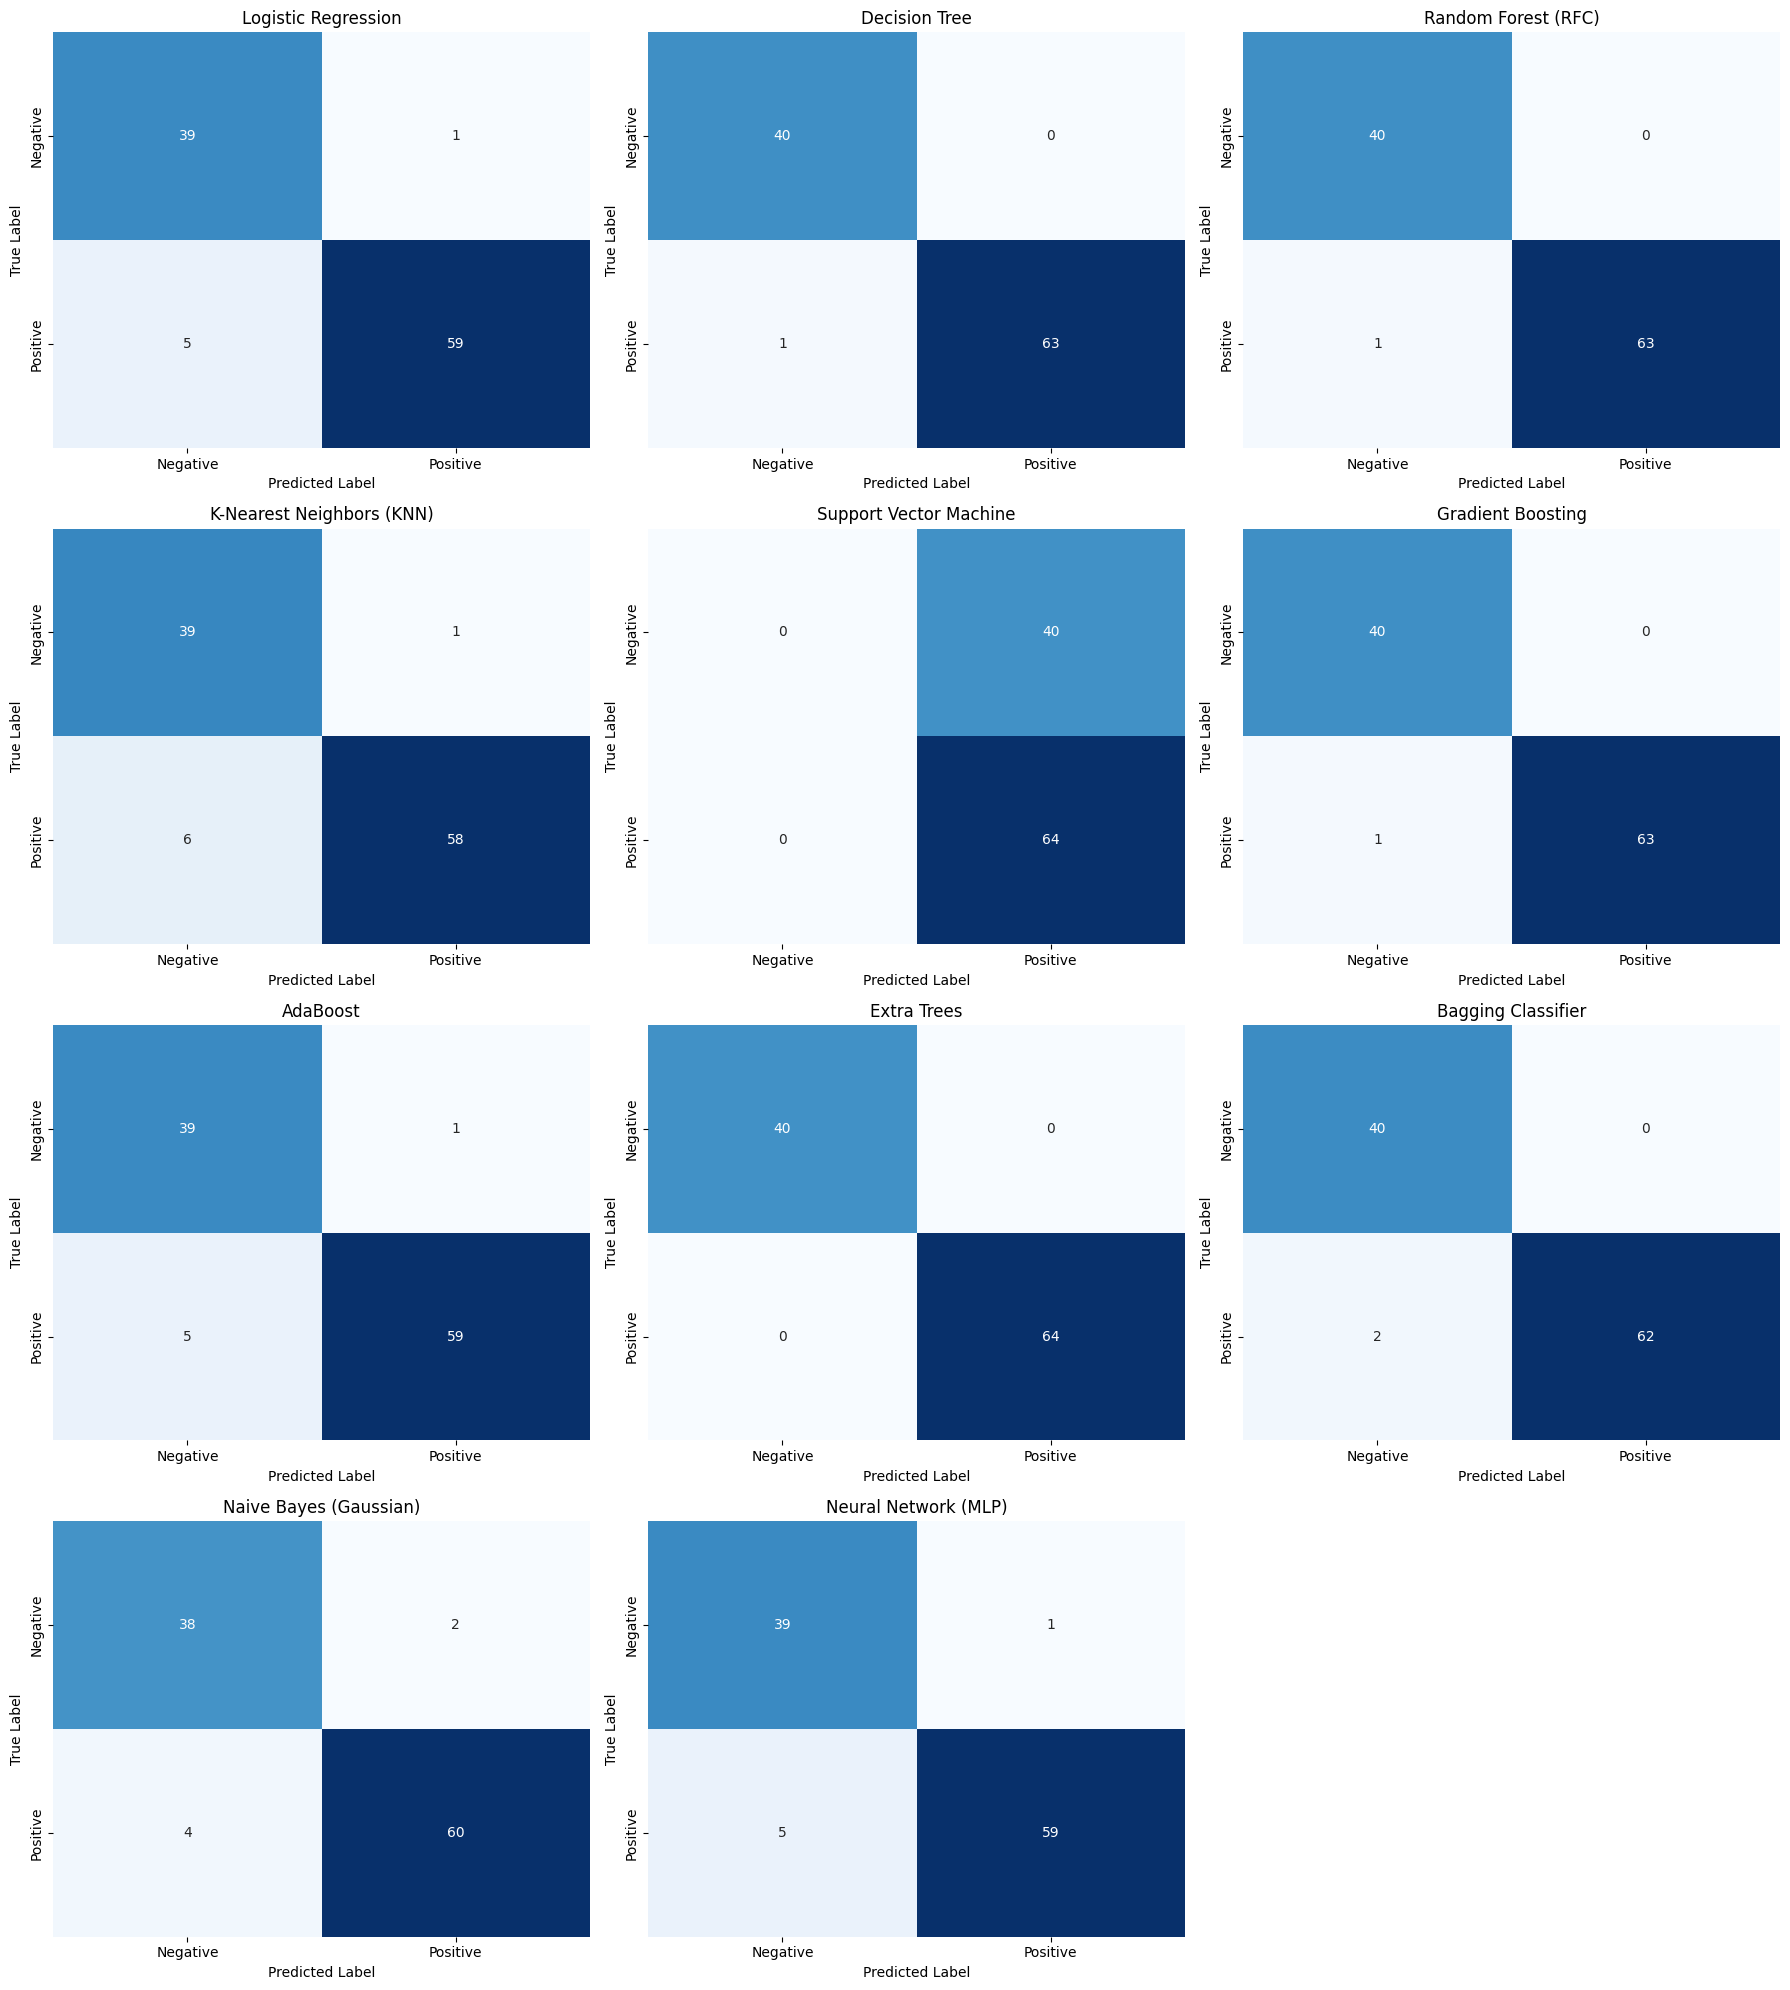

In [ ]:
import math
from sklearn.metrics import confusion_matrix

# تعداد کل مدل‌ها
num_models = len(models)
# محاسبه تعداد سطر و ستون‌های لازم برای شبکه نمودارها
cols = 3
rows = math.ceil(num_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten()

class_names = label_encoders['class'].classes_

for idx, (name, model) in enumerate(models.items()):
    # پیش‌بینی مقادیر بر اساس مدل کنونی
    y_pred_m = model.predict(X_test)

    # محاسبه ماتریس درهم‌ریختگی
    cm_m = confusion_matrix(y_test, y_pred_m)

    # رسم در جایگاه مشخص در ساب‌پلات
    sns.heatmap(cm_m, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=class_names, yticklabels=class_names, cbar=False)

    axes[idx].set_title(f'{name}')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

# حذف ساب‌پلات‌های خالی اضافی در انتهای شکل
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 7. Comparative Confusion Matrices

To conclude our diagnostic analysis, we construct a grid of confusion matrices for all 10 classifiers to visually compare where each algorithm makes misclassifications.